In [ ]:
pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 11.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency,ttest_ind
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,precision_score,recall_score,f1_score,ConfusionMatrixDisplay,RocCurveDisplay
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.contingency_tables import Table
#pip install pgmpy
from pgmpy.estimators import HillClimbSearch, BIC, BayesianEstimator
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
import networkx as nx


#/Breast_Cancer_Cleaned_Data.csv


In [ ]:
#Load the data and review the data. check how many data rows and variables available

cancer_data= pd.read_csv('/content/Breast_Cancer_Cleaned_Data.csv')
print(cancer_data.shape)
display(cancer_data.head())

(2481, 34)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_claudinlow_subtype,cohort,er_status_measured_by_ihc,...,overall_survival_status,pr_status,radio_therapy,relapse_free_status_months,relapse_free_status,sex,3gene_classifier_subtype,tumor_size,tumor_stage,patients_vital_status
0,MB-0000,75,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,claudin-low,1.0,Positve,...,Living,Negative,Yes,138.65,Not Recurred,Female,ER+/HER2- High Prolif,22.0,2.0,Living
1,MB-0002,43,Breast Conserving,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,LumA,1.0,Positve,...,Living,Positive,Yes,83.52,Not Recurred,Female,ER+/HER2- High Prolif,10.0,1.0,Living
2,MB-0005,48,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,Yes,LumB,1.0,Positve,...,Deceased,Positive,No,151.28,Recurred,Female,ER+/HER2- High Prolif,15.0,2.0,Died of Disease
3,MB-0006,47,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,Yes,LumB,1.0,Positve,...,Living,Positive,Yes,162.76,Not Recurred,Female,ER+/HER2- High Prolif,25.0,2.0,Living
4,MB-0008,76,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,Yes,LumB,1.0,Positve,...,Deceased,Positive,Yes,18.55,Recurred,Female,ER+/HER2- High Prolif,40.0,2.0,Died of Disease


Number of records in each survival category:


,number_of_records
overall_survival_status,
Deceased,1535
Living,946


Percentage of records in each survival category:


,percentage
overall_survival_status,
Deceased,61.87
Living,38.13


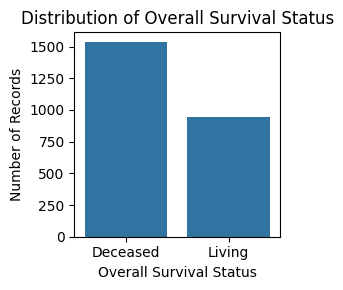

In [ ]:

# Lets looks at the survival outcome, Summary statistic, Distribution
#this is done to udnderstand the overall_survival_status outcome.
#it will help in identfies the details of living and deceased
#This data will hep use to understand the balance between this two groups for building a model


#Count the records in each survival category.
survival_status_counts = cancer_data["overall_survival_status"].value_counts()

print("Number of records in each survival category:")
display(survival_status_counts.to_frame("number_of_records"))

# Calculate the percentage represented by each category.
survival_status_percentages = (cancer_data["overall_survival_status"].value_counts(normalize=True) * 100)

print("Percentage of records in each survival category:")
display(survival_status_percentages.round(2).to_frame("percentage"))

#Lets Create a bar chart to compare the number of records in each category.
plt.figure(figsize=(3, 3))

sns.countplot(
    data=cancer_data,x="overall_survival_status",order=cancer_data["overall_survival_status"].value_counts().index
)

plt.title("Distribution of Overall Survival Status")
plt.xlabel("Overall Survival Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [ ]:
# Select the numerical columns we want to compare
group_measures = ['age_at_diagnosis','tumor_size','lymph_nodes_examined_positive', 'mutation_count','nottingham_prognostic_index']

# Calculate the average for Living and Deceased records
group_averages = cancer_data.groupby('overall_survival_status')[group_measures].mean()
group_averages = group_averages.T
group_averages = group_averages.round(2)
group_averages = group_averages.rename(columns={'Living': 'Living records: mean','Deceased': 'Deceased records: mean'})
print(group_averages)


overall_survival_status        Deceased records: mean  Living records: mean
age_at_diagnosis                                62.14                 56.51
tumor_size                                      28.89                 23.97
lymph_nodes_examined_positive                    2.75                  1.24
mutation_count                                   5.65                  5.32
nottingham_prognostic_index                      4.13                  3.87


,count,mean,std,min,25%,50%,75%,max
age_at_diagnosis,2481.0,59.99,13.03,21.0,50.00,61.00,70.00,96.0
tumor_size,2481.0,27.02,16.45,1.0,17.30,23.00,30.00,182.0
lymph_nodes_examined_positive,2481.0,2.17,4.18,0.0,0.00,0.00,2.00,45.0
mutation_count,2481.0,5.52,3.98,0.0,3.00,5.00,7.00,80.0
nottingham_prognostic_index,2481.0,4.03,1.19,1.0,3.05,4.05,5.04,7.2


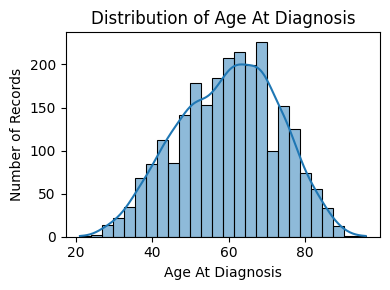

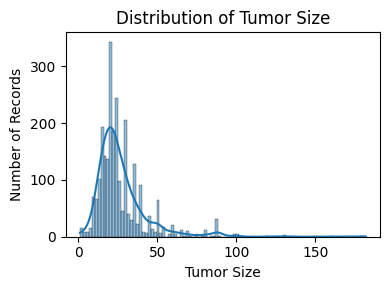

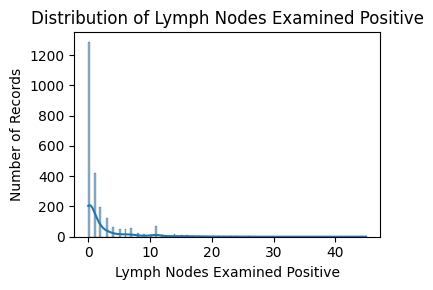

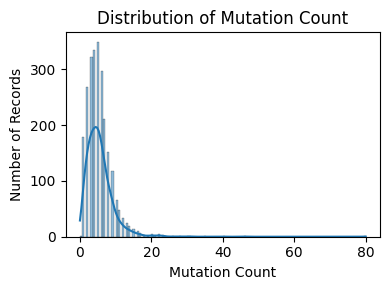

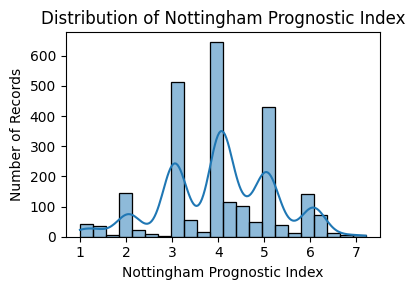

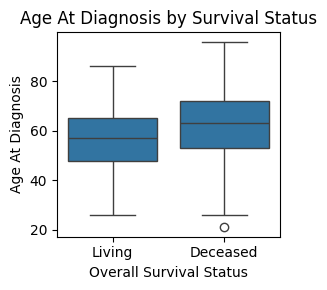

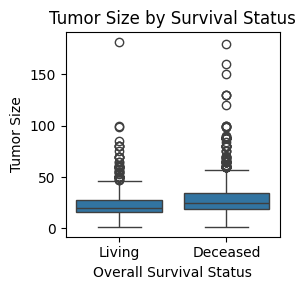

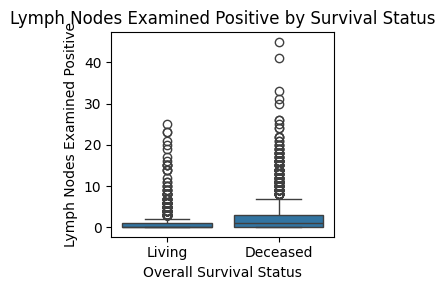

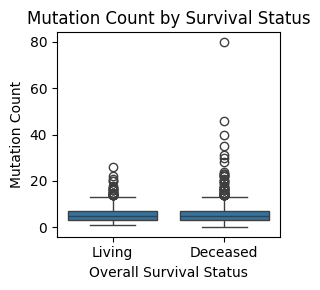

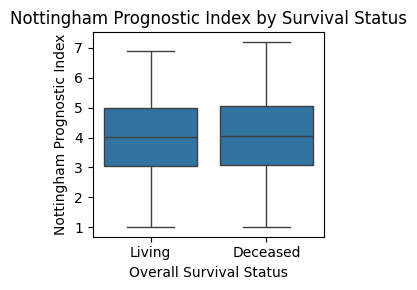

In [ ]:
#lets review on the five varaible
#Age of diagnosis
#tumer size
#Lymph nodes examined psotive
#mutation_count
#Nottingham Progonostic index
#This summary statistics help us understand typical values and variabtion.
#The histogram will show the sap of distribution and Boxplot will help in comparing values for living and deceased

# Define the numeric variables used in the exploratory analysis.
# We will reuse this list in the statistical tests and correlation analysis.

numeric_columns = ["age_at_diagnosis","tumor_size","lymph_nodes_examined_positive","mutation_count","nottingham_prognostic_index"]

# Lets Display the count, mean, standard deviation, minimum, quartiles, and maximum.
numeric_summary = cancer_data[numeric_columns].describe().T
display(numeric_summary.round(2))

# Lets Create a histogram for each numeric variable.This helps us see its
#distribution and whether values are concentrated  in a particular range.

for column_name in numeric_columns:
    plt.figure(figsize=(4, 3))

    sns.histplot(data=cancer_data,x=column_name,kde=True)

    plt.title(f"Distribution of {column_name.replace('_', ' ').title()}")
    plt.xlabel(column_name.replace("_", " ").title())
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

# lets Compare each numeric variable between Living and Deceased groups.
# Boxplots show the median, spread, and potential outliers.

for column_name in numeric_columns:
    plt.figure(figsize=(3, 3))

    sns.boxplot(data=cancer_data, x="overall_survival_status",y=column_name )

    plt.title(
        f"{column_name.replace('_', ' ').title()} by Survival Status"
    )
    plt.xlabel("Overall Survival Status")
    plt.ylabel(column_name.replace("_", " ").title())
    plt.tight_layout()
    plt.show()


Counts by tumor stage and survival status:


overall_survival_status,Deceased,Living
tumor_stage,,
0.0,9,16
1.0,517,329
2.0,872,562
3.0,125,36
4.0,12,3


Percentages within each tumor stage:


overall_survival_status,Deceased,Living
tumor_stage,,
0.0,36.00,64.00
1.0,61.11,38.89
2.0,60.81,39.19
3.0,77.64,22.36
4.0,80.00,20.00


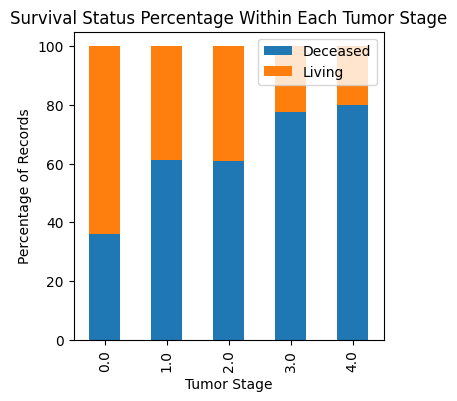

In [ ]:
#Lets compare tumor stage with survival stage. We will see in table format
#with count and percentage chart to understand the data
# Count the records in each combination of tumor stage and survival status.
tumor_stage_survival_counts = pd.crosstab(
    cancer_data["tumor_stage"],
    cancer_data["overall_survival_status"]
)

print("Counts by tumor stage and survival status:")
display(tumor_stage_survival_counts)

# lets Calculate percentages within each tumor stage. Each row adds up to approximately 100%,
# making stages easier to compare.

tumor_stage_survival_percentages = pd.crosstab(cancer_data["tumor_stage"],
    cancer_data["overall_survival_status"],
    normalize="index"
) * 100

print("Percentages within each tumor stage:")
display(tumor_stage_survival_percentages.round(2))

# Plot the percentages as stacked bars.
tumor_stage_survival_percentages.plot(kind="bar",stacked=True,figsize=(4, 4))

plt.title("Survival Status Percentage Within Each Tumor Stage")
plt.xlabel("Tumor Stage")
plt.ylabel("Percentage of Records")
plt.legend()
plt.show()

**Statistical test**

Chi-Square Test for Categorical Variable. Here we will test the relationship between survival status and four categorical variables such as Tumar Stage, ER Status, HER2 status and PR Status. This will help us deterimin whether this is statisical evidence of an association between two categorical variables

In [ ]:

# lets first define the categorical variables we want to test and store the result for each test
categorical_columns = ["tumor_stage","er_status","her2_status","pr_status"]

categorical_test_results = []

# lets create for loop so that we can run a separate test for each categorical variable.
 # and Create a table showing the counts for each combination of the selected variable and survival status.
for column_name in categorical_columns:

    contingency_table = pd.crosstab(cancer_data[column_name],
        cancer_data["overall_survival_status"]
    )

    # Run the test only when the table has multiple categoriesfor both variables.
    if contingency_table.shape[0] > 1 and contingency_table.shape[1] > 1:

        chi_square_result = Table(
            contingency_table.to_numpy()
        ).test_nominal_association()

        # Save the statistic, degrees of freedom, and p-value.
        categorical_test_results.append({"variable": column_name,"chi_square_statistic": chi_square_result.statistic,
                                         "degrees_of_freedom": chi_square_result.df,"p_value": chi_square_result.pvalue})

# Display all test results in one table.
categorical_test_results = pd.DataFrame(categorical_test_results)

display(categorical_test_results.round(6))

,variable,chi_square_statistic,degrees_of_freedom,p_value
0,tumor_stage,27.0450,4,0.0000
1,er_status,0.1601,1,0.6891
2,her2_status,3.3335,1,0.0679
3,pr_status,31.8669,1,0.0000


**************

**Corelation Analysis**
Lets check the correlation heatmap which will help us to identify the relationship before interpreting the prediction model. Correlationvalue close to 1 indicate a strogner psotive relationship. values closer to -1 indeate the stronger negative relationshp and value near 0 indcate a weaker relationship

,age_at_diagnosis,tumor_size,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index
age_at_diagnosis,1.000,0.084,-0.019,0.032,-0.064
tumor_size,0.084,1.000,0.257,0.007,0.380
lymph_nodes_examined_positive,-0.019,0.257,1.000,-0.049,0.588
mutation_count,0.032,0.007,-0.049,1.000,0.009
nottingham_prognostic_index,-0.064,0.380,0.588,0.009,1.000


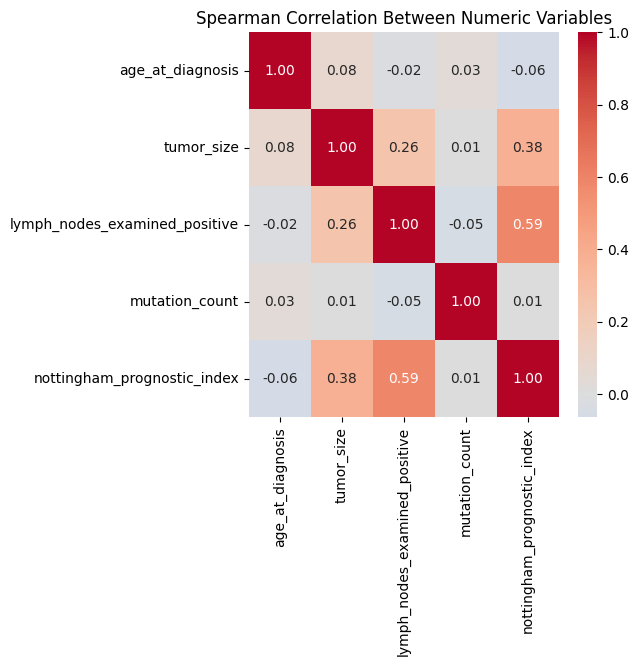

In [ ]:

# Lets Calculate Spearman correlations among the numeric variables.
#Spearman correlation measures how consistently two variables
# move in the same or opposite direction.

spearman_correlation_matrix = cancer_data[numeric_columns].corr(method="spearman")

display(spearman_correlation_matrix.round(3))

# Plot the correlations as a heatmap.
plt.figure(figsize=(5, 5))

sns.heatmap(spearman_correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0)

plt.title("Spearman Correlation Between Numeric Variables")
plt.show()


** Model Selection and Prepration**



Lets seperate the data used to train the model from the data used to evalute. Let's check an 80/20 Split: 80% of eligible records for training and hold back 20% for testing

In [ ]:

# lets define the predictors selected for the main logistic regression model and

candidate_predictors = ["age_at_diagnosis","tumor_size","tumor_stage","neoplasm_histologic_grade",
                        "er_status","her2_status","pr_status","lymph_nodes_examined_positive","mutation_count"]


predictor_columns = [column_name for column_name in candidate_predictors if column_name in cancer_data.columns]

print(predictor_columns)

#lets create a modeling dataset containing only the selected predictors and outcome
model_data = cancer_data[predictor_columns + ["overall_survival_status"]].dropna(subset=["overall_survival_status"]).copy()

# for the outcome lets Encode the 1 = Deceased and 0 = Living
model_data["target_deceased"] = (model_data["overall_survival_status"] == "Deceased").astype(int)

X = model_data[predictor_columns].copy()
y = model_data["target_deceased"].copy()

# lets Split the data before fitting the model
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


numeric_predictors = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_predictors = [column_name for column_name in X_train.columns if column_name not in numeric_predictors]

# LetsConvert categorical variables into numeric indicator columns Learn the columns from the training data, then align the test data
# so both datasets have exactly the same predictor columns
X_train_encoded = pd.get_dummies(X_train,columns=categorical_predictors,drop_first=True,dtype=float)

X_test_encoded = pd.get_dummies(X_test,columns=categorical_predictors,drop_first=True,dtype=float)

X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns,fill_value=0)

# If any missing values are present, use medians calculated from the training data only
training_medians = X_train_encoded.median()

X_train_encoded = X_train_encoded.fillna(training_medians)
X_test_encoded = X_test_encoded.fillna(training_medians)
print("Training records:", len(X_train_encoded))
print("Testing records:", len(X_test_encoded))
print("Encoded predictor count:", X_train_encoded.shape[1])

['age_at_diagnosis', 'tumor_size', 'tumor_stage', 'neoplasm_histologic_grade', 'er_status', 'her2_status', 'pr_status', 'lymph_nodes_examined_positive', 'mutation_count']
Training records: 1984
Testing records: 497
Encoded predictor count: 9


Fit logistic regression using a pipeline. Standardscaler puts numberic features on comparable scales and logistic regression learns the relationship between the predicator and the binary outcome

In [ ]:

logistic_regression_pipeline = Pipeline([("standard_scaler", StandardScaler()),("logistic_regression",LogisticRegression(max_iter=2000, random_state=42))])

#lets Train the model and predict the outcome for each test record
logistic_regression_pipeline.fit(X_train_encoded,y_train)

y_pred = logistic_regression_pipeline.predict(X_test_encoded)

y_probability = logistic_regression_pipeline.predict_proba(X_test_encoded)[:, 1]


**Model Analysis and Evaluation**


Lets evaluaate the model using five measures : Accuracy, precision, recall, F1-Score, and ROC-AUC. Looking at several metrics gives us a more compelte picture than accuracy alone

In [ ]:
# Calculate the main performance measures using test-set predictions

logistic_regression_metrics = pd.DataFrame([{"model": "Logistic Regression","accuracy": accuracy_score(y_test, y_pred),
                                             "precision": precision_score(y_test, y_pred, zero_division=0),"recall": recall_score(y_test, y_pred, zero_division=0),
                                             "f1_score": f1_score(y_test, y_pred, zero_division=0),"roc_auc": roc_auc_score(y_test, y_probability)}])

display(logistic_regression_metrics.round(4))

# Les show detailed performance for both outcome categories
print("Classification report:")
print(classification_report(y_test,y_pred,labels=[0, 1],target_names=["Living", "Deceased"],zero_division=0))

,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.6338,0.6623,0.8306,0.737,0.6952


Classification report:
              precision    recall  f1-score   support

      Living       0.54      0.32      0.40       190
    Deceased       0.66      0.83      0.74       307

    accuracy                           0.63       497
   macro avg       0.60      0.57      0.57       497
weighted avg       0.61      0.63      0.61       497



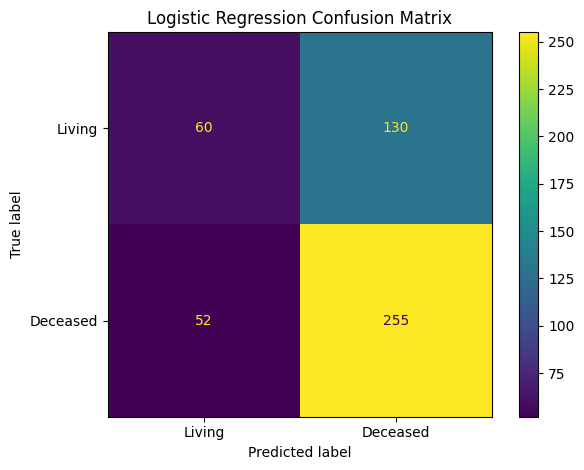

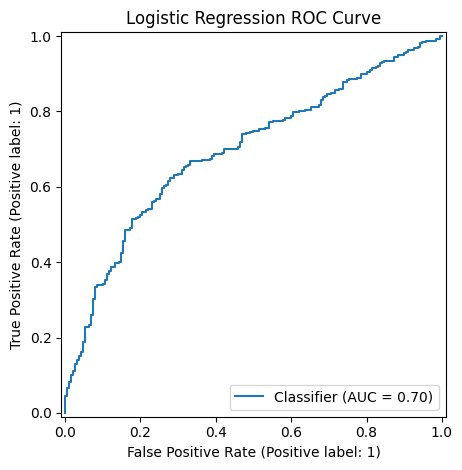

In [ ]:

#The confusion matrix makes it easier to see which records were classified correctly and which were misclassified
#The ROC curve shows the trade off between idenfifying Deceased records and incorrectly classifying lving records ad deceased
# lest display the confusion matrix using readable class labels
confusion_matrix_values = confusion_matrix(y_test,y_pred,labels=[0, 1])

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_values,display_labels=["Living", "Deceased"]).plot(values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

# lets display the ROC curve using the predicted probabilities
RocCurveDisplay.from_predictions(y_test,y_probability)

plt.title("Logistic Regression ROC Curve")
plt.tight_layout()
plt.show()

In [ ]:
#Lets do logistic regression as GLM.
# lets Add an intercept column for the statsmodels model
X_train_glm = sm.add_constant(X_train_encoded,has_constant="add")

# lets Fit a Binomial GLM, which is logistic regression for a binary outcome
glm_model = sm.GLM(y_train,X_train_glm,family=sm.families.Binomial()).fit()
print(glm_model.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:        target_deceased   No. Observations:                 1984
Model:                            GLM   Df Residuals:                     1974
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1211.0
Date:                Wed, 14 Oct 2026   Deviance:                       2421.9
Time:                        01:22:46   Pearson chi2:                 2.02e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1028
Covariance Type:            nonrobust                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

  0%|          | 0/1000000 [00:00<?, ?it/s]

Learned netwrok Relationship  [('age_at_diagnosis', 'er_status'), ('age_at_diagnosis', 'overall_survival_status'), ('tumor_size', 'lymph_nodes_examined_positive'), ('tumor_size', 'age_at_diagnosis'), ('lymph_nodes_examined_positive', 'pr_status'), ('lymph_nodes_examined_positive', 'overall_survival_status'), ('lymph_nodes_examined_positive', 'her2_status'), ('lymph_nodes_examined_positive', 'er_status'), ('tumor_stage', 'lymph_nodes_examined_positive'), ('tumor_stage', 'tumor_size'), ('er_status', 'pr_status'), ('er_status', 'her2_status'), ('her2_status', 'pr_status')]

Is the Bayesian Network valid?
True


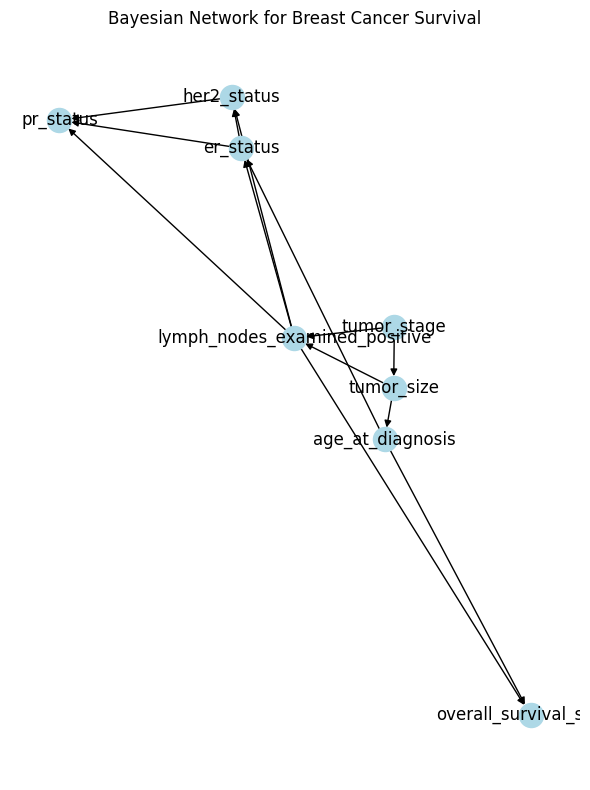


Estimated survival probabilities when tumor size is High:
+-----------------------------------+--------------------------------+
| overall_survival_status           |   phi(overall_survival_status) |
+===================================+================================+
| overall_survival_status(Deceased) |                         0.6558 |
+-----------------------------------+--------------------------------+
| overall_survival_status(Living)   |                         0.3442 |
+-----------------------------------+--------------------------------+

Survival probabilities by tumor-size category:
  Tumor Size Survival Status  Probability
0        Low        Deceased        0.570
1        Low          Living        0.430
2     Medium        Deceased        0.629
3     Medium          Living        0.371
4       High        Deceased        0.656
5       High          Living        0.344


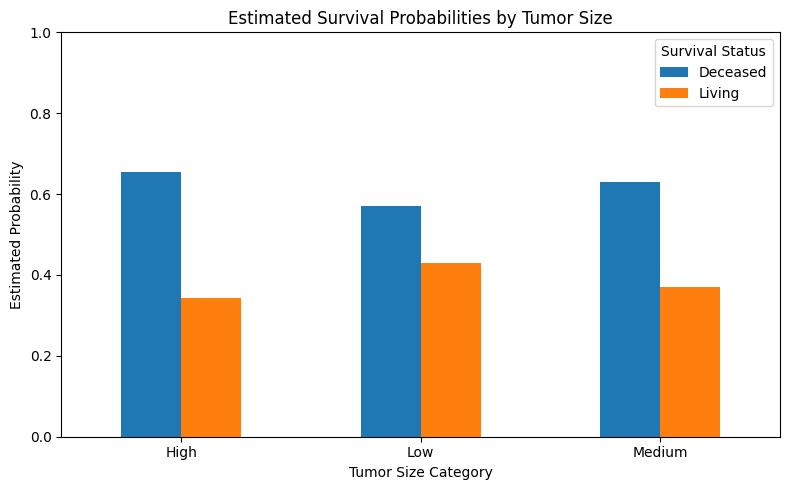

In [ ]:

#Select the variables for the Bayesian Network
bayesian_network_columns = ["age_at_diagnosis","tumor_size","lymph_nodes_examined_positive",
                            "mutation_count","tumor_stage","er_status","her2_status","pr_status","overall_survival_status"]

bayesian_network_data = cancer_data[bayesian_network_columns].dropna().copy()

#Lets convert numeric variables into Low, Medium, and High categories
numeric_variables = ["age_at_diagnosis","tumor_size","lymph_nodes_examined_positive","mutation_count"]

for column in numeric_variables:
    bayesian_network_data[column] = pd.qcut(bayesian_network_data[column].rank(method="first"),q=3,labels=["Low", "Medium", "High"])

# Convert all variables to strings so they are treated as categories
for column in bayesian_network_columns:
    bayesian_network_data[column] = bayesian_network_data[column].astype(str)


# letsLearn the network structure using Hill Climb Search and BIC
structure_search = HillClimbSearch(bayesian_network_data)
learned_structure = structure_search.estimate(scoring_method=BIC(bayesian_network_data))
print('Learned netwrok Relationship ',list(learned_structure.edges()))

bayesian_network_model = DiscreteBayesianNetwork(learned_structure.edges())
bayesian_network_model.add_nodes_from(bayesian_network_columns)


# lets Estimate the conditional probabilities use BayesianEstimator instead of passing equivalent_sample_size to fit()
bayesian_estimator = BayesianEstimator(bayesian_network_model,bayesian_network_data)

estimated_cpds = bayesian_estimator.get_parameters(prior_type="BDeu",equivalent_sample_size=10)

bayesian_network_model.add_cpds(*estimated_cpds)

print("\nIs the Bayesian Network valid?")
print(bayesian_network_model.check_model())


# Print the  the network as a graph
network_graph = nx.DiGraph()
network_graph.add_edges_from(bayesian_network_model.edges())

plt.figure(figsize=(6, 8))
network_positions = nx.spring_layout(network_graph, seed=42)

nx.draw_networkx(network_graph,pos=network_positions,with_labels=True,node_color="lightblue",arrows=True)

plt.title("Bayesian Network for Breast Cancer Survival")
plt.axis("off")
plt.tight_layout()
plt.show()


# Lets Estimate survival probabilities for patients with high tumor size
survival_inference = VariableElimination(bayesian_network_model)
survival_probability = survival_inference.query(variables=["overall_survival_status"],evidence={"tumor_size": "High"},show_progress=False)

print("\nEstimated survival probabilities when tumor size is High:")
print(survival_probability)


# Lets Compare survival probabilities for Low, Medium, and High tumor sizes
survival_results = []

for tumor_category in ["Low", "Medium", "High"]:

    probability_result = survival_inference.query(variables=["overall_survival_status"],evidence={"tumor_size": tumor_category},show_progress=False)

    survival_states = probability_result.state_names["overall_survival_status"]

    for index, survival_status in enumerate(survival_states):
        survival_results.append({"Tumor Size": tumor_category,"Survival Status": survival_status,"Probability": probability_result.values[index]})

survival_table = pd.DataFrame(survival_results)

print("\nSurvival probabilities by tumor-size category:")
print(survival_table.round(3))


# lets plot the survival probability comparison
survival_pivot = survival_table.pivot(index="Tumor Size",columns="Survival Status",values="Probability"
)

survival_pivot.plot(kind="bar", figsize=(8, 5))

plt.title("Estimated Survival Probabilities by Tumor Size")
plt.xlabel("Tumor Size Category")
plt.ylabel("Estimated Probability")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# Treatment-aware Bayesian Network
# This section uses the existing dataset variable: breast_cancer_data.
# It includes treatment records, survival status, and relapse status.
# The results are conditional associations, not proof that treatment caused an outcome.

try:
    from pgmpy.estimators import HillClimbSearch, BIC, BayesianEstimator
    from pgmpy.models import DiscreteBayesianNetwork
    from pgmpy.inference import VariableElimination
    pgmpy_treatment_available = True
except ImportError:
    pgmpy_treatment_available = False
    print("Install pgmpy before running this section: %pip install pgmpy")

if pgmpy_treatment_available:
    bayes_treatment_data = cancer_data[["age_at_diagnosis", "tumor_size","tumor_stage","neoplasm_histologic_grade",
                                        "lymph_nodes_examined_positive", "chemotherapy","hormone_therapy","radio_therapy",
                                        "type_of_breast_surgery","overall_survival_status","relapse_free_status"]    ].copy()

    #Lets  Convert numeric measures into groups so the network is easier to interpret
    bayes_treatment_data["age_group"] = pd.cut(bayes_treatment_data["age_at_diagnosis"], bins=[-np.inf, 50, 65, np.inf],labels=["Younger", "Middle", "Older"]).astype(str)

    bayes_treatment_data["tumor_size_group"] = pd.cut(bayes_treatment_data["tumor_size"],bins=[-np.inf, 20, 50, np.inf],labels=["Small", "Medium", "Large"]).astype(str)

    bayes_treatment_data["lymph_node_group"] = pd.cut(bayes_treatment_data["lymph_nodes_examined_positive"],bins=[-np.inf, 0, 3, np.inf],labels=["None", "Low", "High"]).astype(str)

    bayes_treatment_data["tumor_stage"] = bayes_treatment_data["tumor_stage"].astype(str)
    bayes_treatment_data["neoplasm_histologic_grade"] = (bayes_treatment_data["neoplasm_histologic_grade"].astype(str)
    )

    bayes_treatment_variables = ["age_group","tumor_size_group","tumor_stage","neoplasm_histologic_grade","lymph_node_group",
                                 "chemotherapy","hormone_therapy","radio_therapy","type_of_breast_surgery","overall_survival_status","relapse_free_status"    ]

    bayes_treatment_data = (bayes_treatment_data[bayes_treatment_variables].dropna().astype(str)
    )

    # Lets perform HillClimbSearch and BIC select a candidate network structure
    treatment_hc = HillClimbSearch(bayes_treatment_data)
    treatment_dag = treatment_hc.estimate(scoring_method=BIC(bayes_treatment_data))

    bayesian_treatment_network = DiscreteBayesianNetwork(treatment_dag.edges())
    bayesian_treatment_network.add_nodes_from(bayes_treatment_variables)


    treatment_estimator = BayesianEstimator(bayesian_treatment_network,bayes_treatment_data )
    treatment_cpds = treatment_estimator.get_parameters(prior_type="BDeu",equivalent_sample_size=10)
    bayesian_treatment_network.add_cpds(*treatment_cpds)

    print("Treatment-aware Bayesian Network edges:")
    print(list(bayesian_treatment_network.edges()))
    print("Network check:", bayesian_treatment_network.check_model())

    # Show a useful probability comparison for one example patient profile this is an example for learning, not a real patient's risk estimate.
    treatment_inference = VariableElimination(bayesian_treatment_network)

    example_patient_profile = {age_group": "Older",
        "tumor_stage": "3.0",
        "lymph_node_group": "High"
    }

    treatment_probability_results = []

    for chemotherapy_value in ["No", "Yes"]:
        evidence_for_query = {
            **example_patient_profile,
            "chemotherapy": chemotherapy_value
        }

        survival_posterior = treatment_inference.query(
            variables=["overall_survival_status"],
            evidence=evidence_for_query,
            show_progress=False
        )

        relapse_posterior = treatment_inference.query(
            variables=["relapse_free_status"],
            evidence=evidence_for_query,
            show_progress=False
        )

        survival_probabilities = dict(zip(
            survival_posterior.state_names["overall_survival_status"],
            survival_posterior.values.reshape(-1)
        ))
        relapse_probabilities = dict(zip(
            relapse_posterior.state_names["relapse_free_status"],
            relapse_posterior.values.reshape(-1)
        ))

        treatment_probability_results.append({
            "Example profile": "Older; Stage 3; high positive lymph nodes",
            "Chemotherapy recorded": chemotherapy_value,
            "Estimated probability Living": survival_probabilities.get("Living", np.nan),
            "Estimated probability Deceased": survival_probabilities.get("Deceased", np.nan),
            "Estimated probability Not Recurred": relapse_probabilities.get("Not Recurred", np.nan),
            "Estimated probability Recurred": relapse_probabilities.get("Recurred", np.nan)
        })

    treatment_probability_results = pd.DataFrame(treatment_probability_results)
    display(treatment_probability_results.round(3))

    print(
        "Interpretation reminder: compare the two rows as conditional patterns learned "
        "from this dataset. They do not show what would happen if the same patient were "
        "given or not given chemotherapy. Treatment selection, disease severity, age, "
        "and other unmeasured factors can affect these comparisons."
    )
else:
    print("Run this section after pgmpy is installed.")

  0%|          | 0/1000000 [00:00<?, ?it/s]

Treatment-aware Bayesian Network edges:
[('age_group', 'chemotherapy'), ('chemotherapy', 'hormone_therapy'), ('chemotherapy', 'neoplasm_histologic_grade'), ('chemotherapy', 'radio_therapy'), ('tumor_stage', 'tumor_size_group'), ('tumor_stage', 'type_of_breast_surgery'), ('type_of_breast_surgery', 'radio_therapy'), ('type_of_breast_surgery', 'age_group'), ('lymph_node_group', 'tumor_stage'), ('lymph_node_group', 'chemotherapy'), ('lymph_node_group', 'hormone_therapy'), ('lymph_node_group', 'radio_therapy'), ('lymph_node_group', 'tumor_size_group'), ('hormone_therapy', 'neoplasm_histologic_grade'), ('radio_therapy', 'hormone_therapy'), ('overall_survival_status', 'relapse_free_status'), ('overall_survival_status', 'age_group'), ('overall_survival_status', 'lymph_node_group'), ('relapse_free_status', 'lymph_node_group'), ('relapse_free_status', 'age_group')]
Network check: True


,Example profile,Chemotherapy recorded,Estimated probability Living,Estimated probability Deceased,Estimated probability Not Recurred,Estimated probability Recurred
0,Older; Stage 3; high positive lymph nodes,No,0.129,0.871,0.476,0.524
1,Older; Stage 3; high positive lymph nodes,Yes,0.129,0.871,0.476,0.524


Interpretation reminder: compare the two rows as conditional patterns learned from this dataset. They do not show what would happen if the same patient were given or not given chemotherapy. Treatment selection, disease severity, age, and other unmeasured factors can affect these comparisons.


In [ ]:
#Lets comparte the living and decease group and check association between treatement variables and compare surval modes withour without treatment
# analysis: hypothesis tests, treatment factors, relapse, and model comparison
# Lets  Hypothesis tests for numerical measures: Living vs Deceased
# H0: the two groups have the same population mean for each measure H1: the two group means are different
# This uses the standard independent two-sample t-test taught in class.

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

group_comparison_results_additional = []
for variable in ["age_at_diagnosis","tumor_size","lymph_nodes_examined_positive","mutation_count","nottingham_prognostic_index"]:
    living_values = cancer_data.loc[cancer_data["overall_survival_status"] == "Living", variable].dropna()
    deceased_values = cancer_data.loc[cancer_data["overall_survival_status"] == "Deceased", variable].dropna()
    t_statistic, p_value = ttest_ind(living_values, deceased_values, equal_var=True)
    group_comparison_results_additional.append({"Measure": variable,"Living mean": living_values.mean(),
    "Deceased mean": deceased_values.mean(),"t-statistic": t_statistic,"p-value": p_value})

group_comparison_results_additional = pd.DataFrame(group_comparison_results_additional)
group_comparison_results_additional[["Living mean", "Deceased mean", "t-statistic", "p-value"]] = \
    group_comparison_results_additional[["Living mean", "Deceased mean", "t-statistic", "p-value"]].round(4)
display(group_comparison_results_additional)

# Lets do Chi-square tests for categorical factors and overall survival status
# H0--> the factor and survival status are independent H1--> the factor and survival status are associated.
categorical_survival_variables = ["tumor_stage", "neoplasm_histologic_grade", "chemotherapy", "hormone_therapy", "radio_therapy",
                                  "type_of_breast_surgery", "pr_status", "her2_status", "inferred_menopausal_state"]
chi_square_survival_results = []
for variable in categorical_survival_variables:
    contingency_table = pd.crosstab(cancer_data[variable], cancer_data["overall_survival_status"])
    chi_square, p_value, degrees_freedom, expected_counts = chi2_contingency(contingency_table)
    chi_square_survival_results.append({"Factor": variable,"Chi-square": chi_square,"Degrees of freedom": degrees_freedom,"p-value": p_value})
chi_square_survival_results = pd.DataFrame(chi_square_survival_results).sort_values("p-value")
display(chi_square_survival_results.round(5))

# lets Show the percentage labeled Deceased in each category for selected factors
for variable in ["tumor_stage", "neoplasm_histologic_grade", "chemotherapy", "hormone_therapy", "pr_status"]:
    contingency_table = pd.crosstab(cancer_data[variable], cancer_data["overall_survival_status"], normalize="index").mul(100).round(1)
    print("\nPercentage by", variable)
    display(contingency_table)

# another analysis-> the factors related to recorded relapse status
# from data Not Recurred = 0, Recurred = 1. We do not use relapse-free months as a predictor
relapse_categorical_variables = ["tumor_stage", "neoplasm_histologic_grade", "chemotherapy","hormone_therapy", "radio_therapy",
                                 "type_of_breast_surgery","er_status", "her2_status", "pr_status"]
chi_square_relapse_results = []
for variable in relapse_categorical_variables:
    contingency_table = pd.crosstab(cancer_data[variable], cancer_data["relapse_free_status"] )
    chi_square, p_value, degrees_freedom, expected_counts = chi2_contingency(contingency_table)
    chi_square_relapse_results.append({"Factor": variable,"Chi-square": chi_square,"Degrees of freedom": degrees_freedom,"p-value": p_value})
chi_square_relapse_results = pd.DataFrame(chi_square_relapse_results).sort_values("p-value")
display(chi_square_relapse_results.round(5))

print("Relapse percentage by tumor stage")
relapse_by_stage = pd.crosstab(cancer_data["tumor_stage"], cancer_data["relapse_free_status"], normalize="index").mul(100).round(1)
display(relapse_by_stage)

print("Relapse percentage by histologic grade")
relapse_by_grade = pd.crosstab(cancer_data["neoplasm_histologic_grade"], cancer_data["relapse_free_status"], normalize="index").mul(100).round(1)
display(relapse_by_grade)

# Lets Compare survival prediction with and without treatment variable, This comparison is exploratory: treatment
#choices are not randomized and may reflect disease severity.
survival_predictors_base = ["age_at_diagnosis", "tumor_size", "tumor_stage", "neoplasm_histologic_grade", "er_status", "her2_status", "pr_status", "lymph_nodes_examined_positive", "mutation_count"]
survival_predictors_extended = survival_predictors_base + ["chemotherapy", "hormone_therapy", "radio_therapy", "type_of_breast_surgery"]

def evaluate_classification_model(data, target_name, predictor_names, model_name, estimator):
    model_data_additional = data[predictor_names + [target_name]].dropna().copy()
    X_additional = model_data_additional[predictor_names]
    if target_name == "overall_survival_status":
        y_additional = model_data_additional[target_name].map({"Living": 0, "Deceased": 1})
    else:
        y_additional = model_data_additional[target_name].map({"Not Recurred": 0, "Recurred": 1})

    X_train_additional, X_test_additional, y_train_additional, y_test_additional = train_test_split(X_additional, y_additional,
                                                                                                    test_size=0.20, random_state=42, stratify=y_additional)
    numeric_predictors_additional = X_additional.select_dtypes(include=np.number).columns.tolist()
    categorical_predictors_additional = [column for column in predictor_names if column not in numeric_predictors_additional]
    numeric_pipeline_additional = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
    categorical_pipeline_additional = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor_additional = ColumnTransformer(transformers=[("numeric", numeric_pipeline_additional, numeric_predictors_additional),
     ("categorical", categorical_pipeline_additional, categorical_predictors_additional)])
    model_pipeline_additional = Pipeline(steps=[("preprocessor", preprocessor_additional),("model", estimator)])
    model_pipeline_additional.fit(X_train_additional, y_train_additional)
    predicted_probabilities_additional = model_pipeline_additional.predict_proba(X_test_additional)[:, 1]
    predicted_labels_additional = (predicted_probabilities_additional >= 0.5).astype(int)
    return {"Outcome": target_name,"Model": model_name,"Test records": len(y_test_additional),
            "Accuracy": accuracy_score(y_test_additional, predicted_labels_additional),
            "Precision": precision_score(y_test_additional, predicted_labels_additional, zero_division=0),
            "Recall": recall_score(y_test_additional, predicted_labels_additional, zero_division=0),
            "F1-score": f1_score(y_test_additional, predicted_labels_additional, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test_additional, predicted_probabilities_additional)}

survival_model_comparison_additional = pd.DataFrame([evaluate_classification_model(cancer_data, "overall_survival_status", survival_predictors_base,
                                                                                   "Logistic Regression (clinical factors)", LogisticRegression(max_iter=2000, random_state=42)),
                                                     evaluate_classification_model(cancer_data, "overall_survival_status", survival_predictors_extended,
                                                                                   "Logistic Regression (clinical + treatment)", LogisticRegression(max_iter=2000, random_state=42)),
    evaluate_classification_model(cancer_data, "overall_survival_status", survival_predictors_base,"Random Forest (clinical factors)",
                                  RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1)),
                                                     evaluate_classification_model(cancer_data, "overall_survival_status", survival_predictors_extended,
                                                                                   "Random Forest (clinical + treatment)",
                                                                                   RandomForestClassifier(n_estimators=300,
                                                                                                          min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1))])
display(survival_model_comparison_additional.round(3))

# Lets create a separate model for relapse status, using patient/tumor/treatment factors only We exclude overall_survival_status
# and both follow-up month fields to avoid using outcomes as predictors.
relapse_predictors = survival_predictors_extended
relapse_model_comparison = pd.DataFrame([evaluate_classification_model(cancer_data, "relapse_free_status", relapse_predictors,
                                                                       "Logistic Regression for relapse", LogisticRegression(max_iter=2000, random_state=42)    ),
    evaluate_classification_model(cancer_data, "relapse_free_status", relapse_predictors,"Random Forest for relapse",
                                  RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1))])
display(relapse_model_comparison.round(3))

# if p < 0.05 suggests evidence of an association/difference, not cause and effect.  tests are
# performed here, so treat p-values as exploratory and consider multiple-testing correction.

# Letd doAdjusted GLM to examine which factors remain associated with survivalThe outcome is Deceased = 1 and Living = 0. This is fitted on training data only.
# Odds ratios describe associations after adjusting for the other variables in this model.
import statsmodels.api as sm

survival_predictors_glm_additional = survival_predictors_extended
model_data_glm_additional = cancer_data[survival_predictors_glm_additional + ["overall_survival_status"]].dropna().copy()
X_glm_additional = model_data_glm_additional[survival_predictors_glm_additional].copy()
y_glm_additional = model_data_glm_additional["overall_survival_status"].map({"Living": 0, "Deceased": 1})
X_train_glm_additional, X_test_glm_additional, y_train_glm_additional, y_test_glm_additional = train_test_split(X_glm_additional,
                                                                                                                y_glm_additional, test_size=0.20, random_state=42, stratify=y_glm_additional)
categorical_predictors_glm_additional = X_glm_additional.select_dtypes(include="object").columns.tolist()
X_train_glm_additional = pd.get_dummies(X_train_glm_additional,columns=categorical_predictors_glm_additional,drop_first=True,dtype=float)
X_train_glm_additional = sm.add_constant(X_train_glm_additional, has_constant="add")
glm_model_additional = sm.GLM(y_train_glm_additional,X_train_glm_additional,family=sm.families.Binomial()).fit()

glm_results_additional = pd.DataFrame({"Coefficient": glm_model_additional.params,
                                       "Odds ratio": np.exp(glm_model_additional.params),"p-value": glm_model_additional.pvalues}).drop(index="const", errors="ignore").sort_values("p-value")
display(glm_results_additional.round(4))

,Measure,Living mean,Deceased mean,t-statistic,p-value
0,age_at_diagnosis,56.5074,62.1368,-10.6857,0.0000
1,tumor_size,23.9741,28.8922,-7.3080,0.0000
2,lymph_nodes_examined_positive,1.2378,2.7479,-8.8859,0.0000
3,mutation_count,5.3214,5.6469,-1.9789,0.0479
4,nottingham_prognostic_index,3.8724,4.1260,-5.1938,0.0000


,Factor,Chi-square,Degrees of freedom,p-value
8,inferred_menopausal_state,219.47340,1,0.00000
2,chemotherapy,32.00577,1,0.00000
6,pr_status,31.40153,1,0.00000
3,hormone_therapy,23.36567,1,0.00000
0,tumor_stage,27.04504,4,0.00002
1,neoplasm_histologic_grade,16.52416,2,0.00026
7,her2_status,3.14717,1,0.07606
5,type_of_breast_surgery,1.35224,1,0.24489
4,radio_therapy,0.09123,1,0.76262



Percentage by tumor_stage


overall_survival_status,Deceased,Living
tumor_stage,,
0.0,36.0,64.0
1.0,61.1,38.9
2.0,60.8,39.2
3.0,77.6,22.4
4.0,80.0,20.0



Percentage by neoplasm_histologic_grade


...

Relapse percentage by histologic grade


relapse_free_status,Not Recurred,Recurred
neoplasm_histologic_grade,,
1,75.9,24.1
2,61.8,38.2
3,55.1,44.9


,Outcome,Model,Test records,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,overall_survival_status,Logistic Regression (clinical factors),497,0.634,0.662,0.831,0.737,0.695
1,overall_survival_status,Logistic Regression (clinical + treatment),497,0.672,0.691,0.847,0.761,0.720
2,overall_survival_status,Random Forest (clinical factors),497,0.690,0.780,0.694,0.734,0.745
3,overall_survival_status,Random Forest (clinical + treatment),497,0.716,0.799,0.723,0.759,0.786


,Outcome,Model,Test records,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,relapse_free_status,Logistic Regression for relapse,497,0.640,0.602,0.31,0.409,0.641
1,relapse_free_status,Random Forest for relapse,497,0.648,0.562,0.57,0.566,0.674


,Coefficient,Odds ratio,p-value
age_at_diagnosis,0.0294,1.0298,0.0000
lymph_nodes_examined_positive,0.1205,1.1280,0.0000
tumor_size,0.0202,1.0204,0.0000
type_of_breast_surgery_Mastectomy,-0.4736,0.6228,0.0001
chemotherapy_Yes,-0.5723,0.5642,0.0001
radio_therapy_Yes,-0.4357,0.6468,0.0005
pr_status_Positive,-0.3920,0.6757,0.0008
neoplasm_histologic_grade,0.2408,1.2722,0.0038
mutation_count,0.0199,1.0201,0.1342
hormone_therapy_Yes,0.1199,1.1274,0.2979
